# 13 - Orçamento de Incerteza: Quanto Confiar em um Registro

Os notebooks 01 a 12 trataram o banco de dados como se todos os registros
merecessem a mesma confiança. Este notebook pergunta o quanto uma espécie pode
se afastar da termoquímica de referência. Desde a versão 0.5.0, o `pyglenn`
traz um envelope de erro por espécie, exposto por
`ThermochemicalCalculator.uncertainty`. O envelope resume, em um conjunto de
números independente da temperatura, a diferença entre os polinômios da NASA
empacotados e as tabelas NIST-JANAF: um viés e uma banda de dois sigma para Cp e
H, além de uma banda absoluta de dois sigma para S.

O roteiro é curto. Começamos pelo que o método devolve, medimos quanto do
catálogo está de fato validado, examinamos as espécies que o envelope sinaliza,
confrontamos a banda declarada com uma referência independente e terminamos
propagando a banda para uma entalpia de reação.

In [1]:
import pandas as pd

from pyglenn import ThermochemicalCalculator

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. O que o método devolve

`uncertainty(species_id, temperature)` devolve um dicionário. A temperatura é
verificada contra a faixa da espécie mas não altera os números, porque o
envelope é um único resumo para todo o intervalo.

| chave | significado |
|-----|---------|
| `cp_rel_bias` | desvio relativo médio de Cp, em porcentagem |
| `cp_rel_2sigma` | banda relativa de dois sigma de Cp, em porcentagem |
| `h_rel_bias` | desvio relativo médio da entalpia padronizada, em porcentagem |
| `h_rel_2sigma` | banda relativa de dois sigma de H, em porcentagem |
| `s_abs_2sigma` | banda de dois sigma de S, absoluta, em J/(mol K) |
| `n_ref_points` | número de pontos de referência por trás do envelope |
| `source` | `nist-janaf` para espécies validadas, `extrapolated` caso contrário |

Duas propriedades decidem como o envelope pode ser usado. A banda não depende da
temperatura: os mesmos números aparecem a 300, 1000 e 3000 K, então uma cifra
cobre um intervalo em que os polinômios mudam de forma. E ela não é estimada
espécie por espécie em todo o catálogo. Os 2 017 registros extrapolados
compartilham apenas duas constantes distintas, então suas bandas são idênticas
até o último dígito.


In [3]:
with ThermochemicalCalculator() as calc:
    co2 = calc.get_available_species("CO2", exact_match=True)[0]
    envelope = calc.uncertainty(co2.id, 1000.0)

for key, value in envelope.items():
    print(f"{key:15s}: {value}")

species_id     : 316
species_name   : CO2
temperature    : 1000.0
cp_rel_bias    : 0.1874
cp_rel_2sigma  : 1.4138
h_rel_bias     : 0.0221
h_rel_2sigma   : 0.1668
s_abs_2sigma   : 0.0912
n_ref_points   : 16
source         : nist-janaf


## 2. Quanto do catálogo está validado

O rótulo em `source` importa mais do que os números. Uma espécie validada foi
comparada ponto a ponto com dados tabelados de referência. O restante carrega uma
banda padrão que veio do estudo de validação, não de um ajuste a essa espécie
específica.

A figura abaixo coloca lado a lado a divisão e a banda que cada grupo carrega.


In [4]:
with ThermochemicalCalculator() as calc:
    catalogue = calc.get_available_species("")
    rows = []
    outside = 0
    for s in catalogue:
        low, high = calc.db.get_temperature_bounds(s.id)
        if not low <= 298.15 <= high:
            outside += 1
        env = calc.uncertainty(s.id, 0.5 * (low + high))
        rows.append({
            "species": s.name,
            "source": "missing" if env is None else env["source"],
            "cp_bias": None if env is None else env["cp_rel_bias"],
            "cp_2sigma": None if env is None else env["cp_rel_2sigma"],
        })

bands = pd.DataFrame(rows)
print(f"records whose valid range excludes 298.15 K: {outside}")
bands["source"].value_counts()

records whose valid range excludes 298.15 K: 416


source
extrapolated    2017
nist-janaf        18
Name: count, dtype: int64

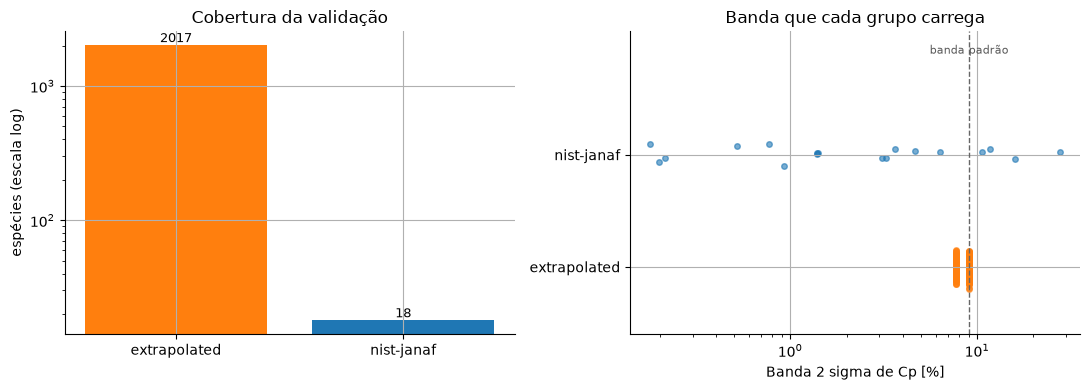

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

counts = bands["source"].value_counts()
tint = {"nist-janaf": "tab:blue", "extrapolated": "tab:orange", "missing": "0.6"}
ax1.bar(counts.index, counts.values, color=[tint[k] for k in counts.index])
ax1.set_yscale("log")
ax1.set_ylabel("espécies (escala log)")
ax1.set_title("Cobertura da validação")
for i, v in enumerate(counts.values):
    ax1.annotate(f"{v}", (i, v), ha="center", va="bottom", fontsize=9)

rng = np.random.default_rng(0)
groups = ["extrapolated", "nist-janaf"]
for row, label in enumerate(groups):
    band = bands.loc[bands["source"] == label, "cp_2sigma"].dropna()
    jitter = rng.normal(0.0, 0.05, len(band))
    ax2.scatter(band, row + jitter, s=16, alpha=0.6, color=tint[label])
default_band = bands.loc[bands["source"] == "extrapolated", "cp_2sigma"].median()
ax2.axvline(default_band, color="0.4", ls="--", lw=1)
ax2.annotate("banda padrão", (default_band, 1.9), ha="center", fontsize=8, color="0.35")
ax2.set_xscale("log")
ax2.set_yticks(range(len(groups)))
ax2.set_yticklabels(groups)
ax2.set_ylim(-0.6, 2.1)
ax2.set_xlabel("Banda 2 sigma de Cp [%]")
ax2.set_title("Banda que cada grupo carrega")
plt.tight_layout()
plt.show()

O desequilíbrio é grande. Apenas dezoito espécies foram validadas à mão e as outras
dois mil e dezessete herdam o envelope padrão. Não é um defeito da
biblioteca, é uma afirmação sobre o custo de validar, e deveria moderar qualquer
alegação de exatidão para uma espécie arbitrária.

Nem todos os registros podem ser consultados à temperatura ambiente. Em 416 das
2 035 espécies, 298.15 K está fora da faixa válida, e a chamada levanta exceção em
vez de devolver uma banda. O laço acima usa o ponto médio de cada faixa por isso.


## 3. Espécies sinalizadas pelo envelope

O envelope se justifica como ferramenta de triagem. Entre as espécies validadas
usadas neste notebook, o dióxido de carbono fica em 1.4 por cento em Cp, o
oxigênio em 0.8 e o nitrogênio em 0.2; a água chega a 3.1, e as entradas
extrapoladas carregam a banda padrão de cerca de 9 por cento.

In [6]:
names = ["CO2", "H2O", "O2", "N2", "CH4", "C2H5OH"]

rows = []
with ThermochemicalCalculator() as calc:
    for name in names:
        s = calc.get_available_species(name, exact_match=True)[0]
        env = calc.uncertainty(s.id, 1000.0)
        rows.append({
            "species": s.name,
            "source": env["source"],
            "Cp bias [%]": env["cp_rel_bias"],
            "Cp 2sigma [%]": env["cp_rel_2sigma"],
            "H 2sigma [%]": env["h_rel_2sigma"],
            "S 2sigma [J/mol/K]": env["s_abs_2sigma"],
        })

envelopes = pd.DataFrame(rows).set_index("species").round(2)
envelopes

,source,Cp bias [%],Cp 2sigma [%],H 2sigma [%],S 2sigma [J/mol/K]
species,,,,,
CO2,nist-janaf,0.190,1.410,0.170,0.090
H2O,nist-janaf,1.100,3.100,1.630,1.170
O2,nist-janaf,0.100,0.770,0.280,0.150
N2,nist-janaf,0.030,0.180,0.020,0.010
CH4,nist-janaf,8.820,27.610,13.550,17.290
C2H5OH,extrapolated,0.000,9.070,4.300,5.100


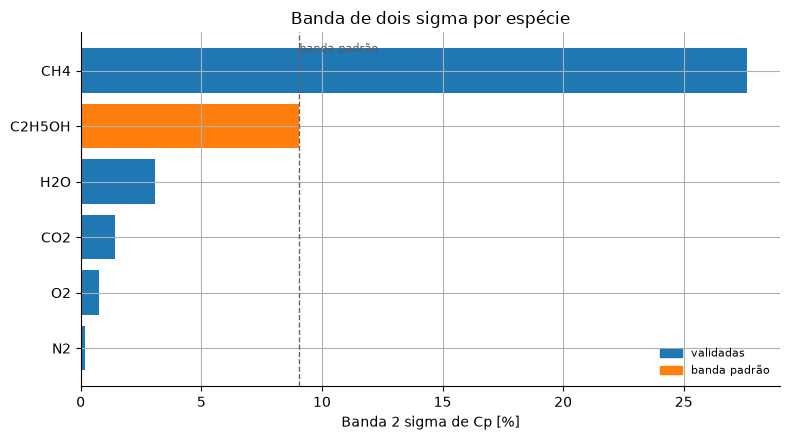

In [7]:
from matplotlib.patches import Patch

order = envelopes.sort_values("Cp 2sigma [%]")
default_band = envelopes.loc[envelopes["source"] == "extrapolated", "Cp 2sigma [%]"].iloc[0]
colour = ["tab:orange" if s == "extrapolated" else "tab:blue" for s in order["source"]]

fig, ax = plt.subplots()
ax.barh(order.index, order["Cp 2sigma [%]"], color=colour)
ax.axvline(default_band, color="0.4", ls="--", lw=1)
ax.annotate("banda padrão", (default_band, len(order) - 0.5), va="top", fontsize=8, color="0.35")
ax.set_xlabel("Banda 2 sigma de Cp [%]")
ax.set_title("Banda de dois sigma por espécie")
ax.legend(handles=[Patch(color="tab:blue", label="validadas"),
                   Patch(color="tab:orange", label="banda padrão")],
          frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

O metano é a exceção, com 27.6 por cento, uma ordem de grandeza acima das
demais. Um sinal desse tamanho não prova que o registro esteja errado, mas
estabelece onde olhar primeiro. As duas seções seguintes seguem essa pista: as
âncoras a 298.15 K e depois uma comparação com uma referência independente ao
longo da faixa de temperatura.

## 4. Acompanhamento de uma espécie sinalizada

A primeira pergunta diante de um registro sinalizado é se as âncoras
fundamentais se sustentam. Três valores bastam: a capacidade calorífica, a
entropia e a entalpia de formação a 298.15 K. Os valores de referência do metano
são amplamente tabelados e a comparação exige um único laço.

In [8]:
anchors = {                      # NIST reference values for CH4(g)
    "Cp(298.15 K) [J/mol/K]": 35.69,
    "S(298.15 K) [J/mol/K]": 186.25,
    "dHf(298.15 K) [kJ/mol]": -74.87,
}

with ThermochemicalCalculator() as calc:
    ch4 = calc.get_available_species("CH4", exact_match=True)[0]
    props = calc.calculate_properties(ch4.id, 298.15)
    computed = {
        "Cp(298.15 K) [J/mol/K]": props.cp,
        "S(298.15 K) [J/mol/K]": props.s,
        "dHf(298.15 K) [kJ/mol]": props.h_relative / 1000.0,
    }

for label, reference in anchors.items():
    dev = 100.0 * (computed[label] - reference) / abs(reference)
    print(f"{label:24s} pyglenn {computed[label]:9.3f}   NIST {reference:9.3f}   dev {dev:+.3f} %")

Cp(298.15 K) [J/mol/K]   pyglenn    35.691   NIST    35.690   dev +0.004 %
S(298.15 K) [J/mol/K]    pyglenn   186.371   NIST   186.250   dev +0.065 %
dHf(298.15 K) [kJ/mol]   pyglenn   -74.600   NIST   -74.870   dev +0.361 %


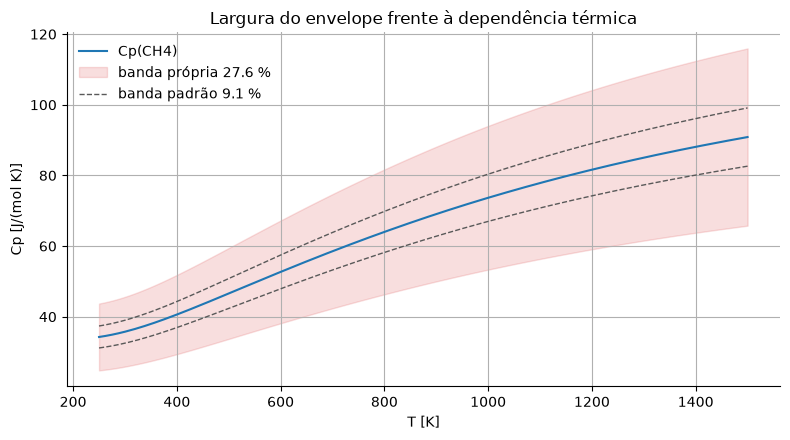

In [9]:
temps = np.linspace(250.0, 1500.0, 200)
with ThermochemicalCalculator() as calc:
    ch4_id = calc.get_available_species("CH4", exact_match=True)[0].id
    ethanol_id = calc.get_available_species("C2H5OH", exact_match=True)[0].id
    cp = np.array([calc.calculate_properties(ch4_id, T).cp for T in temps])
    own = calc.uncertainty(ch4_id, 1000.0)["cp_rel_2sigma"]
    default_band = calc.uncertainty(ethanol_id, 298.15)["cp_rel_2sigma"]

fig, ax = plt.subplots()
ax.plot(temps, cp, color="tab:blue", label="Cp(CH4)")
ax.fill_between(temps, cp * (1 - own / 100), cp * (1 + own / 100),
                color="tab:red", alpha=0.15, label="banda própria {:.1f} %".format(own))
for sign in (+1, -1):
    ax.plot(temps, cp * (1 + sign * default_band / 100), color="0.35", ls="--", lw=1,
            label="banda padrão {:.1f} %".format(default_band) if sign > 0 else None)
ax.set_xlabel("T [K]")
ax.set_ylabel("Cp [J/(mol K)]")
ax.set_title("Largura do envelope frente à dependência térmica")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

As três âncoras ficam perto da referência: 0.004 por cento na capacidade
calorífica, 0.07 por cento na entropia e 0.36 por cento na entalpia de formação.
O registro é sólido perto da temperatura ambiente, e a banda sinalizada não se
explica por uma entalpia de formação deslocada nem por uma constante de entropia
errada. O gráfico de corredor acrescenta a outra consequência: uma banda medida
uma única vez vira uma cunha que se alarga com a temperatura.

## 5. Verificação independente da banda declarada

O envelope informa o que o polinômio deveria perder, não o que ele perde de fato.
Medir isso exige uma referência externa ao banco empacotado. O NIST publica
coeficientes de Shomate para as mesmas espécies, como um ajuste separado aos
mesmos dados calorimétricos, e um único segmento cobre a faixa usada na maior
parte deste notebook.

A comparação avalia as duas descrições de Cp na mesma malha, da temperatura
inferior de cada segmento até seu limite superior. A última coluna divide a banda
de dois sigma declarada pelo maior desvio observado.

In [10]:
# NIST Shomate coefficients for Cp (A, B, C, D, E) and the segment limits
SHOMATE = {
    "N2":  ((28.98641, 1.853978, -9.647459, 16.63537, 0.000117), 200.0, 500.0),
    "O2":  ((31.32234, -20.23531, 57.86644, -36.50624, -0.007374), 200.0, 700.0),
    "CO2": ((24.99735, 55.18696, -33.69137, 7.948387, -0.136638), 298.0, 1200.0),
    "H2O": ((30.09200, 6.832514, 6.793435, -2.534480, 0.082139), 298.0, 1700.0),
    "CH4": ((-0.703029, 108.4773, -42.52157, 5.862788, 0.678565), 298.0, 1300.0),
}


def shomate_cp(coefficients, temperature):
    a, b, c, d, e = coefficients
    t = temperature / 1000.0
    return a + b * t + c * t**2 + d * t**3 + e / t**2


rows = []
with ThermochemicalCalculator() as calc:
    for name, (coefficients, low, high) in SHOMATE.items():
        species = calc.get_available_species(name, exact_match=True)[0]
        grid = np.linspace(low, high, 60)
        library = np.array([calc.calculate_properties(species.id, T).cp for T in grid])
        reference = shomate_cp(coefficients, grid)
        relative = 100.0 * (library - reference) / reference
        envelope = calc.uncertainty(species.id, 0.5 * (low + high))
        rows.append({
            "species": name,
            "range [K]": f"{low:.0f}-{high:.0f}",
            "max |dev| [%]": np.abs(relative).max(),
            "declared 2sigma [%]": envelope["cp_rel_2sigma"],
            "ratio": envelope["cp_rel_2sigma"] / np.abs(relative).max(),
        })

check = pd.DataFrame(rows).set_index("species").round(2)
check

,range [K],max |dev| [%],declared 2sigma [%],ratio
species,,,,
N2,200-500,0.020,0.180,10.980
O2,200-700,0.090,0.770,8.130
CO2,298-1200,0.060,1.410,22.730
H2O,298-1700,0.770,3.100,4.050
CH4,298-1300,4.030,27.610,6.850


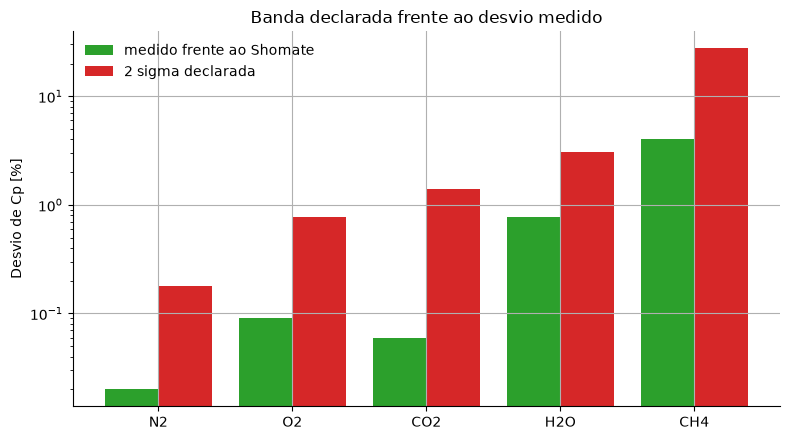

In [11]:
fig, ax = plt.subplots()
position = np.arange(len(check))
ax.bar(position - 0.2, check["max |dev| [%]"], width=0.4,
       color="tab:green", label="medido frente ao Shomate")
ax.bar(position + 0.2, check["declared 2sigma [%]"], width=0.4,
       color="tab:red", label="2 sigma declarada")
ax.set_yscale("log")
ax.set_xticks(position)
ax.set_xticklabels(check.index)
ax.set_ylabel("Desvio de Cp [%]")
ax.set_title("Banda declarada frente ao desvio medido")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

A banda declarada é de quatro a vinte e três vezes maior que o maior desvio
encontrado aqui, e a discrepância é sistemática demais para ser ruído. A
ordenação, no entanto, se mantém: o metano fica pior e o nitrogênio melhor, então
o envelope continua servindo de triagem. Ele não é uma barra de erro calibrada, e
citá-lo como tal, por exemplo mais ou menos 1.4 por cento no dióxido de carbono,
exagera o erro em mais de uma ordem de grandeza.

De onde vem a diferença não está documentado. O resumo publicado traz a banda e o
número de pontos de referência, não os resíduos por trás deles. A faixa é a
origem provável, porque dezesseis pontos distribuídos em um intervalo que chega a
6000 K incluem temperaturas em que o polinômio extrapola. A verificação acima não
resolve essa pergunta, e não precisa. Dentro da janela em que este notebook
trabalha, a banda é conservadora e a ordem das espécies é confiável.

## 6. Propagação da banda para uma entalpia de reação

Para uma combinação linear, como uma entalpia de reação, as bandas se combinam em
quadratura com os coeficientes estequiométricos como pesos, desde que os erros
sejam independentes. O exemplo abaixo usa a combustão completa do metano a
298.15 K, trata a banda relativa de H como se valesse para a entalpia padronizada
de cada espécie e mantém os vieses em uma coluna separada para que seu efeito
possa ser medido.

In [12]:
reaction = {"CH4": -1.0, "O2": -2.0, "CO2": +1.0, "H2O": +2.0}

terms = []
with ThermochemicalCalculator() as calc:
    for name, nu in reaction.items():
        species = calc.get_available_species(name, exact_match=True)[0]
        h = calc.calculate_properties(species.id, 298.15).h_relative / 1000.0
        envelope = calc.uncertainty(species.id, 298.15)
        terms.append({
            "species": name,
            "nu": nu,
            "H [kJ/mol]": h,
            "2sigma [kJ/mol]": abs(h) * envelope["h_rel_2sigma"] / 100.0,
            "source": envelope["source"],
            "h_rel_bias [%]": envelope["h_rel_bias"],
        })

table = pd.DataFrame(terms).set_index("species")
table["|nu| x 2sigma [kJ/mol]"] = (table["nu"] * table["2sigma [kJ/mol]"]).abs()

dH = float((table["nu"] * table["H [kJ/mol]"]).sum())
band = float((table["|nu| x 2sigma [kJ/mol]"] ** 2).sum() ** 0.5)
bias_shift = float((table["nu"] * table["H [kJ/mol]"] * table["h_rel_bias [%]"] / 100.0).sum())

print(table.round(2))
print(f"\nDelta H_rxn(298.15 K) = {dH:8.1f} kJ/mol")
print(f"combined 2sigma       = {band:8.1f} kJ/mol  ({100 * band / abs(dH):.1f} % of the enthalpy)")
print(f"systematic shift from the biases = {bias_shift:+.2f} kJ/mol")

            nu  H [kJ/mol]  2sigma [kJ/mol]      source  h_rel_bias [%]  \
species                                                                   
CH4     -1.000     -74.600           10.110  nist-janaf           4.610   
O2      -2.000      -0.000            0.000  nist-janaf           0.090   
CO2      1.000    -393.510            0.660  nist-janaf           0.020   
H2O      2.000    -241.830            3.940  nist-janaf           0.530   

         |nu| x 2sigma [kJ/mol]  
species                          
CH4                      10.110  
O2                        0.000  
CO2                       0.660  
H2O                       7.890  

Delta H_rxn(298.15 K) =   -802.6 kJ/mol
combined 2sigma       =     12.8 kJ/mol  (1.6 % of the enthalpy)
systematic shift from the biases = +0.77 kJ/mol


In [13]:
reaction = {"C2H5OH": -1.0, "O2": -3.0, "CO2": +2.0, "H2O": +3.0}

contributions = {}
with ThermochemicalCalculator() as calc:
    for name, nu in reaction.items():
        species = calc.get_available_species(name, exact_match=True)[0]
        h = calc.calculate_properties(species.id, 298.15).h_relative / 1000.0
        envelope = calc.uncertainty(species.id, 298.15)
        contributions[name] = (nu, abs(h) * envelope["h_rel_2sigma"] / 100.0, envelope["source"])

quadrature = sum((nu * sigma) ** 2 for nu, sigma, _ in contributions.values()) ** 0.5
linear = sum(abs(nu) * sigma for nu, sigma, _ in contributions.values())

for name, (nu, sigma, source) in contributions.items():
    print(f"{name:8s} nu={nu:+4.1f}  2sigma={sigma:6.2f} kJ/mol  ({source})")
print(f"quadrature          {quadrature:6.2f} kJ/mol")
print(f"perfect correlation {linear:6.2f} kJ/mol")

C2H5OH   nu=-1.0  2sigma= 10.10 kJ/mol  (extrapolated)
O2       nu=-3.0  2sigma=  0.00 kJ/mol  (nist-janaf)
CO2      nu=+2.0  2sigma=  0.66 kJ/mol  (nist-janaf)
H2O      nu=+3.0  2sigma=  3.94 kJ/mol  (nist-janaf)
quadrature           15.61 kJ/mol
perfect correlation  23.24 kJ/mol


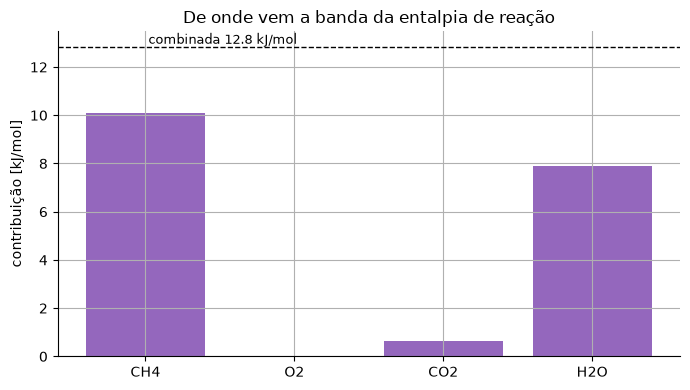

In [14]:
contrib = table["|nu| x 2sigma [kJ/mol]"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(contrib.index, contrib.values, color="tab:purple")
ax.axhline(band, color="k", ls="--", lw=1)
ax.annotate("combinada {:.1f} kJ/mol".format(band), (0.02, band), va="bottom", fontsize=9)
ax.set_ylabel("contribuição [kJ/mol]")
ax.set_title("De onde vem a banda da entalpia de reação")
plt.tight_layout()
plt.show()

A banda combinada de cerca de 13 kJ/mol corresponde a 1.6 por cento da entalpia
de reação, e quase toda ela vem do combustível. Essa assimetria é típica: a
espécie com maior entalpia de formação domina o orçamento, de modo que um
combustível validado vale mais do que um produto validado.

Duas correções importam quando a receita é aplicada em outro caso. Os vieses são
sistemáticos e não aleatórios; ao somá-los, esta entalpia se desloca cerca de
0.8 kJ/mol, algo que a quadratura sozinha não mostra. E a quadratura supõe erros
independentes, o que aqui vale apenas porque as quatro espécies são validadas. Os
2 017 registros extrapolados compartilham uma única constante, então dois deles
são perfeitamente correlacionados e suas contribuições se somam linearmente. Para
a combustão do etanol, cujo combustível é extrapolado, a quadratura dá
15.6 kJ/mol contra 23.2 kJ/mol da soma linear, uma diferença de quase cinquenta
por cento.

## 7. O que fazer com isso

Confira o rótulo de origem antes de confiar em uma espécie que sustenta uma
conclusão. Se o registro é validado, cite a banda junto ao valor calculado, com a
faixa em que foi verificada. Se é extrapolado, diga isso, e trate o orçamento de
uma reação com essa espécie como limite superior e não como medição. Se uma banda
parecer anômala, compare a espécie com uma tabela independente antes de usá-la em
um modelo quantitativo. O envelope reduz a busca, não substitui a referência.